In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("P685_alzheimers_disease_data.csv")

In [3]:
df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


In [4]:
df.shape

(2149, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [6]:
# Statistical Summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientID,2149.0,5825.000000,620.507185,4751.000000,5288.000000,5825.000000,6362.000000,6899.000000
Age,2149.0,74.908795,8.990221,60.000000,67.000000,75.000000,83.000000,90.000000
Gender,2149.0,0.506282,0.500077,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2149.0,0.697534,0.996128,0.000000,0.000000,0.000000,1.000000,3.000000
EducationLevel,2149.0,1.286645,0.904527,0.000000,1.000000,1.000000,2.000000,3.000000
BMI,2149.0,27.655697,7.217438,15.008851,21.611408,27.823924,33.869778,39.992767
Smoking,2149.0,0.288506,0.453173,0.000000,0.000000,0.000000,1.000000,1.000000
AlcoholConsumption,2149.0,10.039442,5.757910,0.002003,5.139810,9.934412,15.157931,19.989293
PhysicalActivity,2149.0,4.920202,2.857191,0.003616,2.570626,4.766424,7.427899,9.987429
DietQuality,2149.0,4.993138,2.909055,0.009385,2.458455,5.076087,7.558625,9.998346


In [7]:
#Identifying Numerical and Categorical Features

numerical_columns = df.select_dtypes(include=np.number).columns

categorical_columns = df.select_dtypes(exclude=np.number).columns

print("Numerical Features\n",numerical_columns)

print("\nCategorical Features\n",categorical_columns)

Numerical Features
 Index(['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI',
       'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
       'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease',
       'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP',
       'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
       'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness', 'Diagnosis'],
      dtype='object')

Categorical Features
 Index(['DoctorInCharge'], dtype='object')


In [8]:
# Checking missing values
df.isnull().sum()

PatientID                    0
Age                          0
Gender                       0
Ethnicity                    0
EducationLevel               0
BMI                          0
Smoking                      0
AlcoholConsumption           0
PhysicalActivity             0
DietQuality                  0
SleepQuality                 0
FamilyHistoryAlzheimers      0
CardiovascularDisease        0
Diabetes                     0
Depression                   0
HeadInjury                   0
Hypertension                 0
SystolicBP                   0
DiastolicBP                  0
CholesterolTotal             0
CholesterolLDL               0
CholesterolHDL               0
CholesterolTriglycerides     0
MMSE                         0
FunctionalAssessment         0
MemoryComplaints             0
BehavioralProblems           0
ADL                          0
Confusion                    0
Disorientation               0
PersonalityChanges           0
DifficultyCompletingTasks    0
Forgetfu

In [9]:
# Checking duplicates
df.duplicated().sum()

np.int64(0)

In [10]:
# Check unique values
for col in df.columns:
    print(col)
    print(df[col].unique())
    print("-"*50)

PatientID
[4751 4752 4753 ... 6897 6898 6899]
--------------------------------------------------
Age
[73 89 74 86 68 75 72 87 78 84 64 69 63 65 82 77 71 83 79 67 66 70 85 60
 88 62 81 61 80 90 76]
--------------------------------------------------
Gender
[0 1]
--------------------------------------------------
Ethnicity
[0 3 1 2]
--------------------------------------------------
EducationLevel
[2 0 1 3]
--------------------------------------------------
BMI
[22.92774923 26.82768119 17.79588244 ... 15.47647896 15.29991122
 33.28973831]
--------------------------------------------------
Smoking
[0 1]
--------------------------------------------------
AlcoholConsumption
[13.29721773  4.54252382 19.55508453 ...  4.59467018  8.67450518
  7.89070315]
--------------------------------------------------
PhysicalActivity
[6.32711247 7.61988454 7.84498779 ... 9.88600229 6.35428175 6.57099338]
--------------------------------------------------
DietQuality
[1.34721431 0.51876714 1.82633466 ... 8.1

In [11]:
# Removing irrelevant columns
df.drop(["PatientID","DoctorInCharge"],axis=1,inplace=True)

In [12]:
df.head()

,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
0,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,9.025679,...,6.518877,0,0,1.725883,0,0,0,1,0,0
1,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,7.151293,...,7.118696,0,0,2.592424,0,0,0,0,1,0
2,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,9.673574,...,5.895077,0,0,7.119548,0,1,0,1,0,0
3,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,8.392554,...,8.965106,0,1,6.481226,0,0,0,0,0,0
4,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,5.597238,...,6.045039,0,0,0.014691,0,0,1,1,0,0


# Visualization

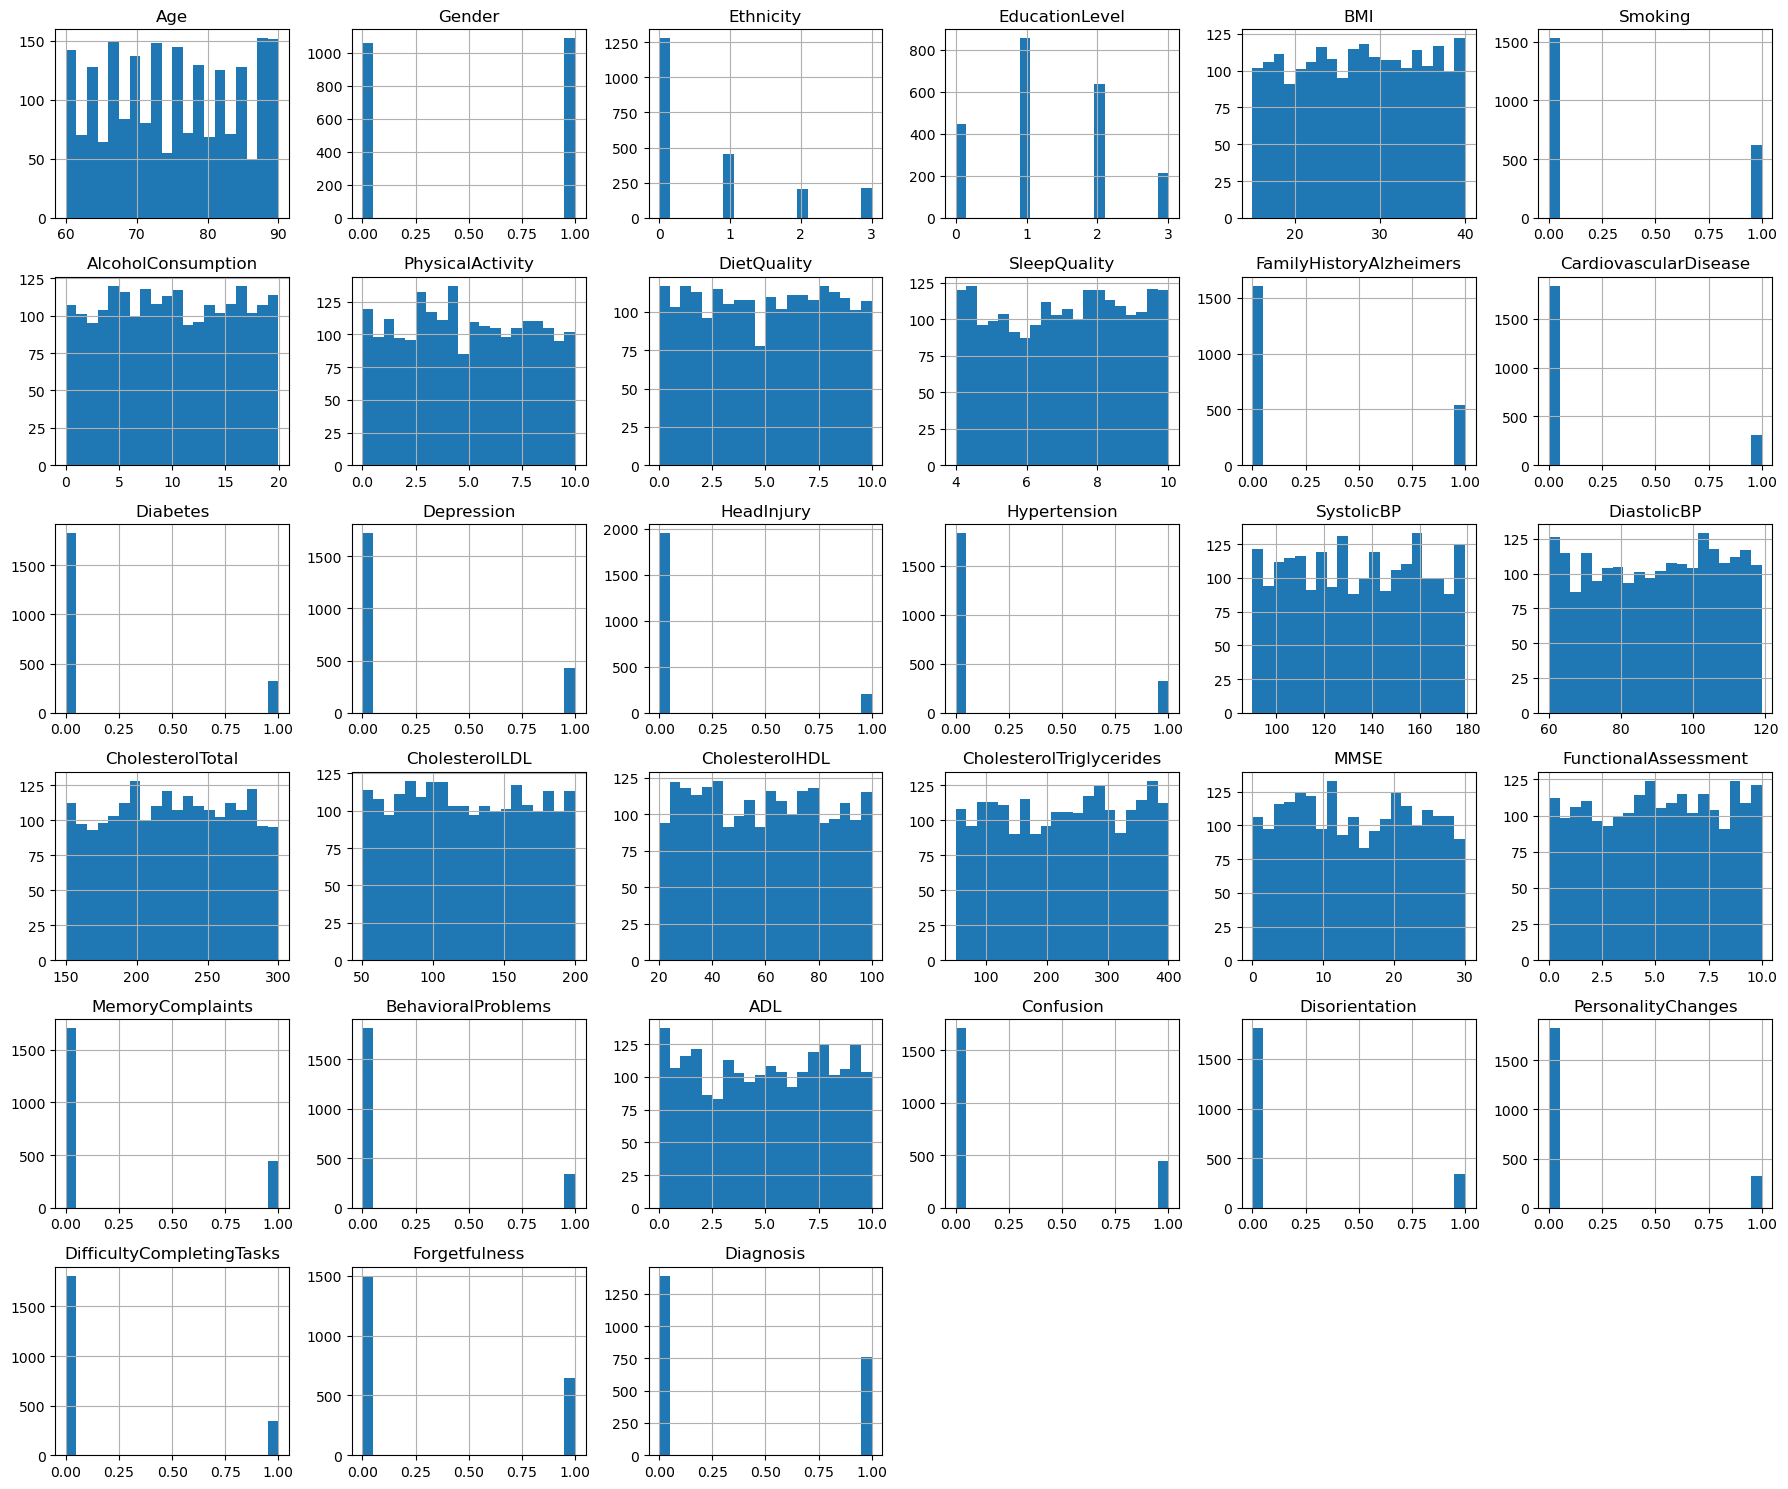

In [13]:
# Distribution of Numerical Features
df.hist(figsize=(18,15),bins=20)

plt.tight_layout()

plt.show()

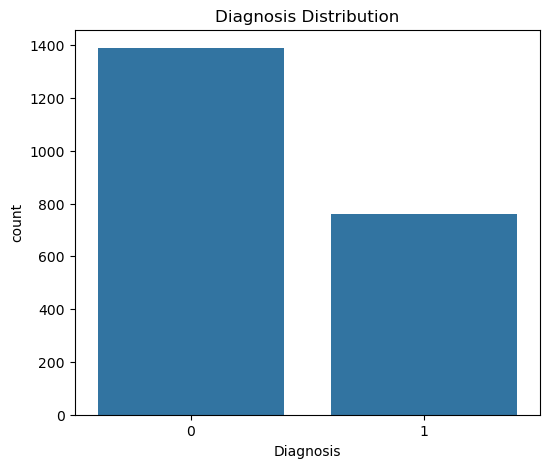

In [14]:
# Target Variable Distribution
plt.figure(figsize=(6,5))
sns.countplot(x='Diagnosis',data=df)
plt.title("Diagnosis Distribution")
plt.show()

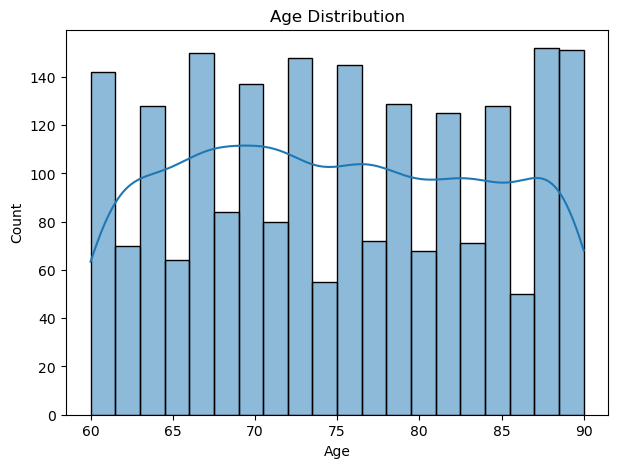

In [15]:
# Distribution of Age
plt.figure(figsize=(7,5))
sns.histplot(df['Age'],bins=20,kde=True)
plt.title("Age Distribution")
plt.show()

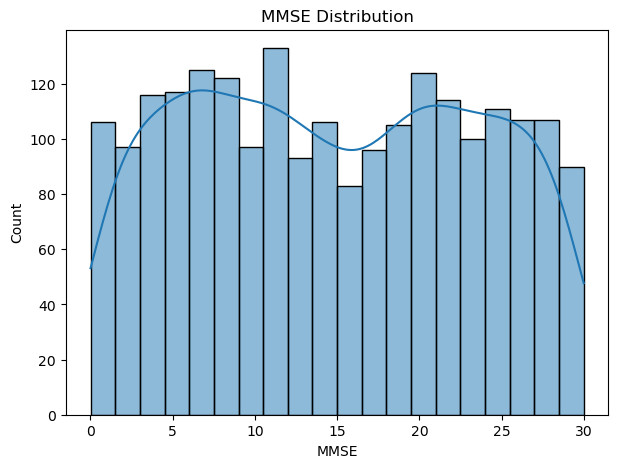

In [16]:
# MMSE Score Distribution
plt.figure(figsize=(7,5))

sns.histplot(df['MMSE'],bins=20,kde=True)

plt.title("MMSE Distribution")

plt.show()

# Boxplots(Outlier Detection)

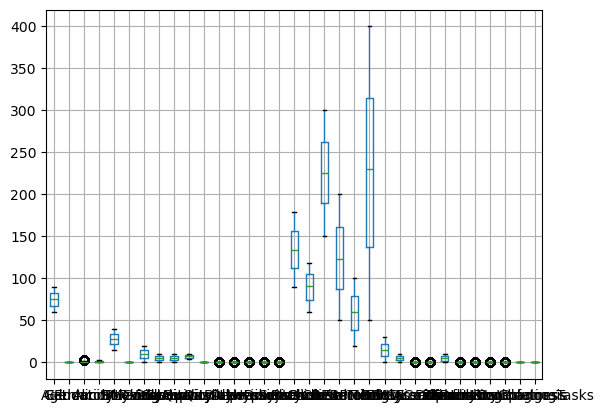

In [17]:
df.boxplot()
plt.show()

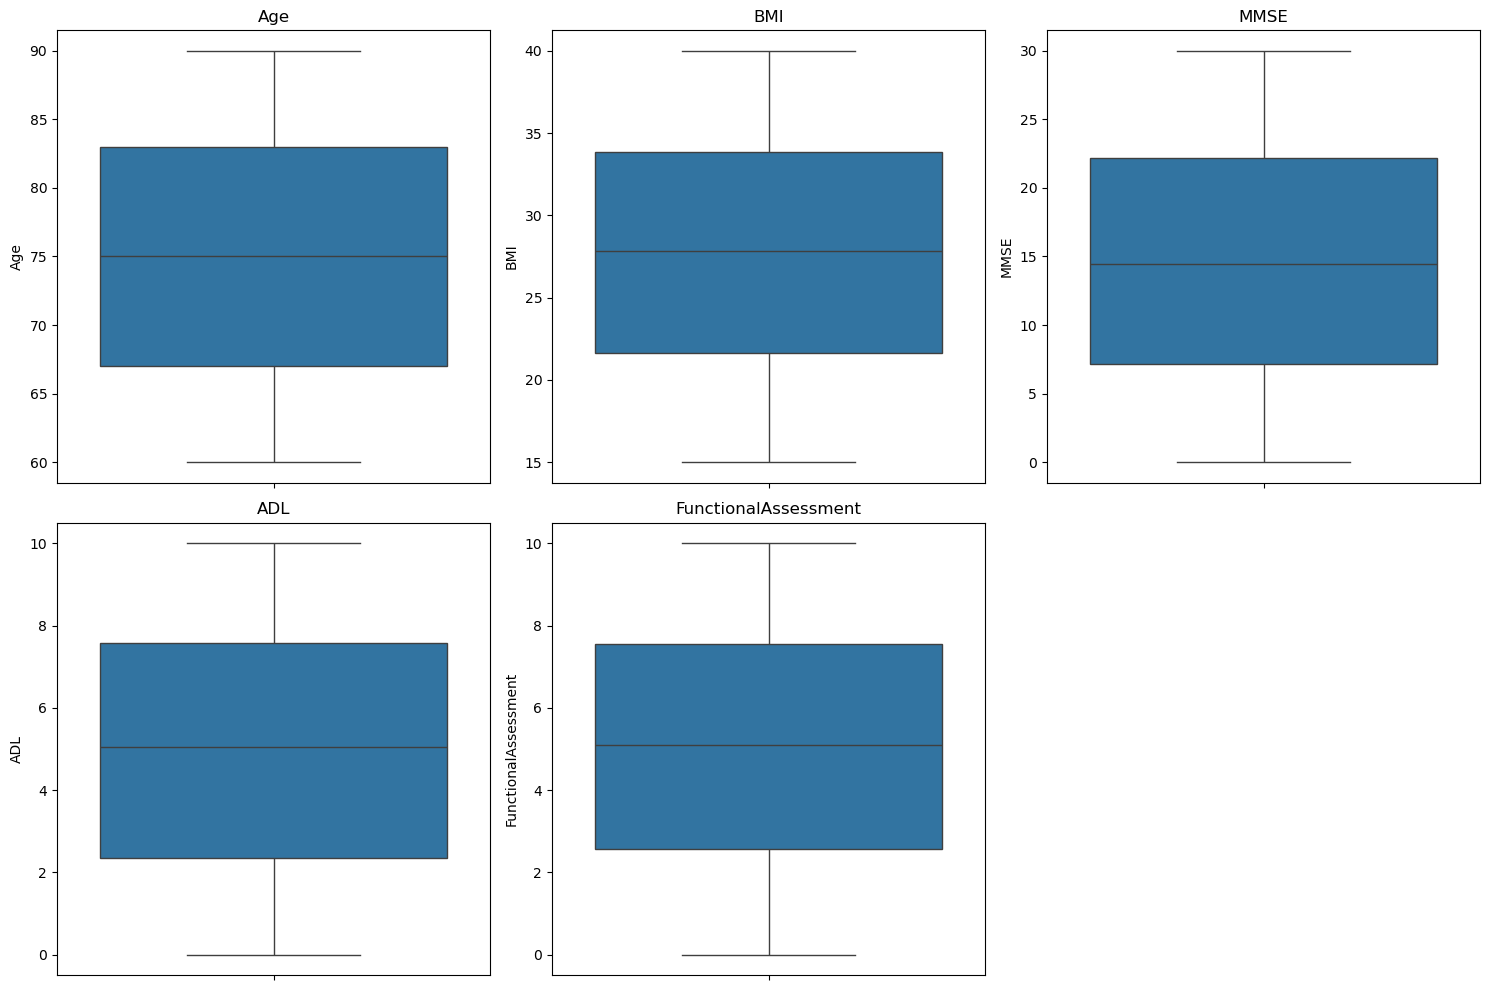

In [18]:
plt.figure(figsize=(15,10))

columns=['Age','BMI','MMSE','ADL','FunctionalAssessment']

for i,col in enumerate(columns):

    plt.subplot(2,3,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()

plt.show()

# Correlaation Heatmap

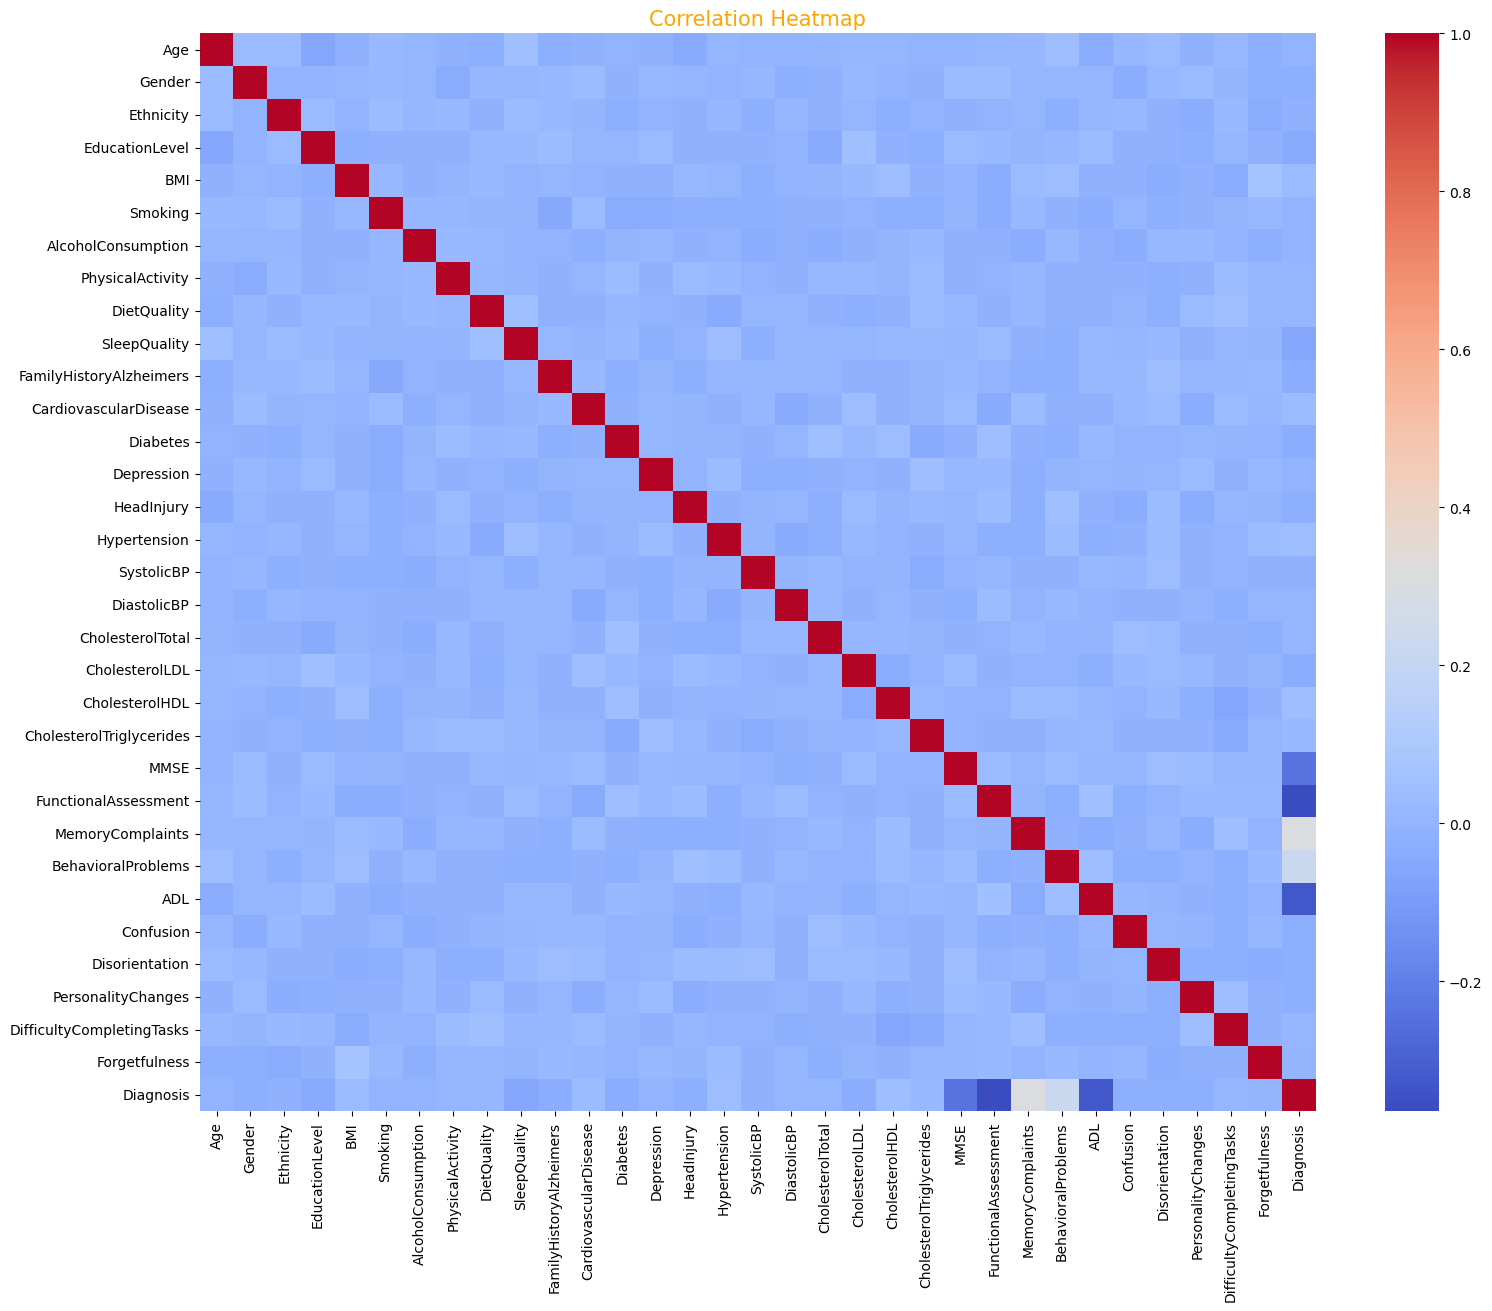

In [19]:
plt.figure(figsize=(18,14))

sns.heatmap(df.corr(),cmap='coolwarm')

plt.title("Correlation Heatmap",fontsize=15,color='Orange')

plt.show()

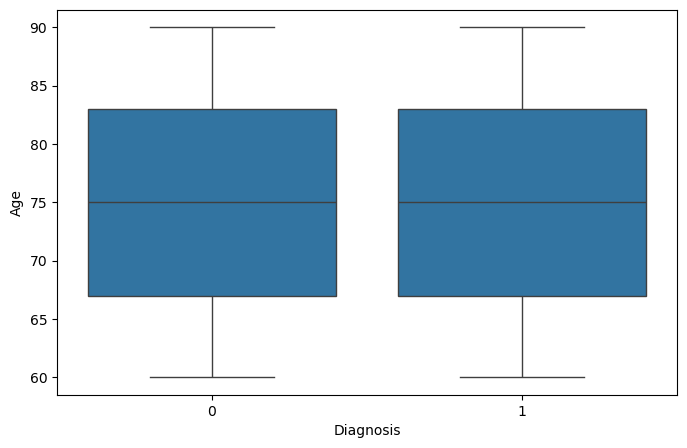

In [20]:
# Realationship between age and Target Variable
plt.figure(figsize=(8,5))

sns.boxplot(x='Diagnosis',y='Age',data=df)

plt.show()

# Pair Plot

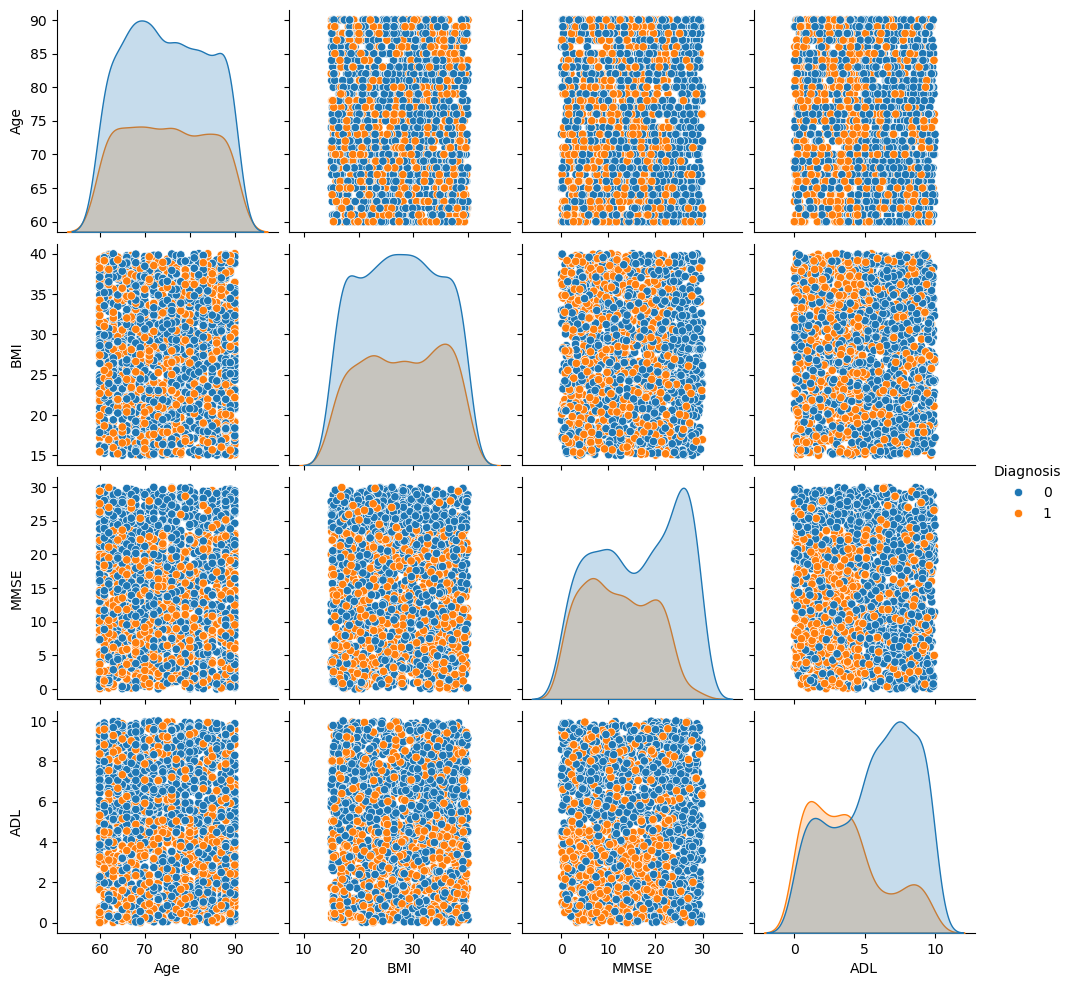

In [21]:
columns=['Age','BMI','MMSE','ADL','Diagnosis']
sns.pairplot(df[columns],hue='Diagnosis')
plt.show()

In [22]:
# Correlation with Target Variable
correlation=df.corr()

correlation['Diagnosis'].sort_values(ascending=False)

Diagnosis                    1.000000
MemoryComplaints             0.306742
BehavioralProblems           0.224350
CholesterolHDL               0.042584
Hypertension                 0.035080
CardiovascularDisease        0.031490
BMI                          0.026343
CholesterolTriglycerides     0.022672
DifficultyCompletingTasks    0.009069
DietQuality                  0.008506
CholesterolTotal             0.006394
PhysicalActivity             0.005945
DiastolicBP                  0.005293
Forgetfulness               -0.000354
Smoking                     -0.004865
Age                         -0.005488
Depression                  -0.005893
AlcoholConsumption          -0.007618
Ethnicity                   -0.014782
SystolicBP                  -0.015615
Confusion                   -0.019186
PersonalityChanges          -0.020627
Gender                      -0.020975
HeadInjury                  -0.021411
Disorientation              -0.024648
Diabetes                    -0.031508
CholesterolL

# Feature Engineering

In [23]:
# Create BMI Categories
df['BMI_Category']=pd.cut(df['BMI'],bins=[0,18.5,25,30,100],labels=['Underweight','Normal','Overweight','Obese'])

In [24]:
# Create Age groups
df['Age_Group']=pd.cut(df['Age'],
                       bins=[60,70,80,90],
                       labels=['60-70','71-80','81-90'])

# Encoding

In [25]:
bmi_encoder = LabelEncoder()
age_encoder = LabelEncoder()

df['BMI_Category']=bmi_encoder.fit_transform(df['BMI_Category'])
df['Age_Group']=bmi_encoder.fit_transform(df['Age_Group'])

In [26]:
df.skew(numeric_only=True)

Age                          0.045964
Gender                      -0.025148
Ethnicity                    1.230215
EducationLevel               0.209118
BMI                         -0.026715
Smoking                      0.934260
AlcoholConsumption           0.018415
PhysicalActivity             0.044973
DietQuality                 -0.012058
SleepQuality                -0.069630
FamilyHistoryAlzheimers      1.141945
CardiovascularDisease        2.026465
Diabetes                     1.953350
Depression                   1.496689
HeadInjury                   2.812844
Hypertension                 1.973834
SystolicBP                   0.009971
DiastolicBP                 -0.054470
CholesterolTotal            -0.018674
CholesterolLDL               0.036233
CholesterolHDL               0.042206
CholesterolTriglycerides    -0.032923
MMSE                         0.032382
FunctionalAssessment        -0.034576
MemoryComplaints             1.439838
BehavioralProblems           1.888867
ADL         

In [27]:
# Split the target and features
features=df.drop(columns='Diagnosis')
target=df[['Diagnosis']]

# Trian Test split

In [28]:
x_train,x_test,y_train,y_test=train_test_split(features,target,train_size=0.8,stratify=target,random_state=30)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1719, 34)
(430, 34)
(1719, 1)
(430, 1)


# Feature Scaling

In [29]:
std_slr=StandardScaler()

x_train[['Age','BMI','MMSE','ADL','FunctionalAssessment']]=std_slr.fit_transform(x_train[['Age','BMI','MMSE','ADL','FunctionalAssessment']])
x_test[['Age','BMI','MMSE','ADL','FunctionalAssessment']]=std_slr.transform(x_test[['Age','BMI','MMSE','ADL','FunctionalAssessment']])

In [30]:
x_train.head()

,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,BMI_Category,Age_Group
136,0.123852,0,0,1,0.554513,0,6.260216,3.697977,7.987123,5.177030,...,0,0,-0.813754,0,0,0,0,0,1,1
269,-1.110037,0,0,1,0.248494,0,9.426422,5.275822,9.755343,6.856580,...,0,0,-1.282781,0,0,1,0,0,2,0
1105,0.909054,0,0,1,1.003670,1,12.419039,5.441339,6.305599,6.252803,...,1,0,-1.568462,0,0,1,0,0,1,2
871,-1.110037,0,0,0,-0.759243,1,5.330385,2.194416,0.612264,4.246876,...,0,0,1.041143,0,0,0,0,1,0,0
1926,1.582085,0,0,0,-0.880176,0,16.059360,9.169833,5.676018,4.008388,...,0,0,1.578650,1,1,0,1,0,0,2


# Model Buildng

# Model-1: Logistic Regression

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report

In [32]:
log_model=LogisticRegression(max_iter=1000,random_state=100)
log_model.fit(x_train,y_train)
y_pred=log_model.predict(x_test)

In [33]:
# Model Evaluation
acc_scr=accuracy_score(y_test,y_pred)
print('===Logistic model Accuracy Score===\n',acc_scr)
print('==classification report==\n',classification_report(y_test,y_pred))

===Logistic model Accuracy Score===
 0.8348837209302326
==classification report==
               precision    recall  f1-score   support

           0       0.88      0.86      0.87       278
           1       0.76      0.78      0.77       152

    accuracy                           0.83       430
   macro avg       0.82      0.82      0.82       430
weighted avg       0.84      0.83      0.84       430



# Model-2: Random Forest

In [34]:
from sklearn.ensemble import RandomForestClassifier

In [35]:
rf_model=RandomForestClassifier(n_estimators=100,criterion='gini',min_samples_split=5,max_features=0.9,random_state=100)
rf_model.fit(x_train,y_train)
y_pred_rf=rf_model.predict(x_test)

In [36]:
# Model Evaluation
rf_acc_scr=accuracy_score(y_test,y_pred_rf)
print('===Random Forest model Accuracy Score===\n',rf_acc_scr)
print('==classification report==\n',classification_report(y_test,y_pred_rf))

===Random Forest model Accuracy Score===
 0.9488372093023256
==classification report==
               precision    recall  f1-score   support

           0       0.95      0.97      0.96       278
           1       0.95      0.90      0.93       152

    accuracy                           0.95       430
   macro avg       0.95      0.94      0.94       430
weighted avg       0.95      0.95      0.95       430



# Model-3: XGBoost Model

In [37]:
!pip install xgboost

In [38]:
from xgboost import XGBClassifier

In [39]:
xgb_model=XGBClassifier(n_estimators=100,learning_rate=0.8,random_state=100)
xgb_model.fit(x_train,y_train)
xgb_pred=xgb_model.predict(x_test)

In [40]:
# Model Evaluation
xgb_acc_scr=accuracy_score(y_test,xgb_pred)
print('===XGBoost Accuracy Score===\n',xgb_acc_scr)
print('==classification report==\n',classification_report(y_test,xgb_pred))

===XGBoost Accuracy Score===
 0.9534883720930233
==classification report==
               precision    recall  f1-score   support

           0       0.95      0.97      0.96       278
           1       0.95      0.91      0.93       152

    accuracy                           0.95       430
   macro avg       0.95      0.94      0.95       430
weighted avg       0.95      0.95      0.95       430



# Model-4:Gradient Boost

In [41]:
from sklearn.ensemble import GradientBoostingClassifier

In [42]:
grb_model=GradientBoostingClassifier(n_estimators=100,learning_rate=0.8,min_samples_split=2,max_features=0.9,random_state=30)
grb_model.fit(x_train,y_train)
grb_pred=grb_model.predict(x_test)

In [43]:
grb_acc_scr=accuracy_score(y_test,grb_pred)
print('===Gradient boost Accuracy Score===\n',grb_acc_scr)
print('==classification report==\n',classification_report(y_test,grb_pred))

===Gradient boost Accuracy Score===
 0.9116279069767442
==classification report==
               precision    recall  f1-score   support

           0       0.94      0.92      0.93       278
           1       0.87      0.89      0.88       152

    accuracy                           0.91       430
   macro avg       0.90      0.91      0.90       430
weighted avg       0.91      0.91      0.91       430



# Comparision of models based on Accuracy

In [44]:
data= {'Models':['Logistic Regression','Random Forest','XG-Boost','Gradient Boost'],
      'Accuracy Scores':[acc_scr,rf_acc_scr,xgb_acc_scr,grb_acc_scr]}

df=pd.DataFrame(data)
# Sorting the df in ascending order based on accuracy score
df.sort_values(by='Accuracy Scores',ascending=False)

,Models,Accuracy Scores
2,XG-Boost,0.953488
1,Random Forest,0.948837
3,Gradient Boost,0.911628
0,Logistic Regression,0.834884


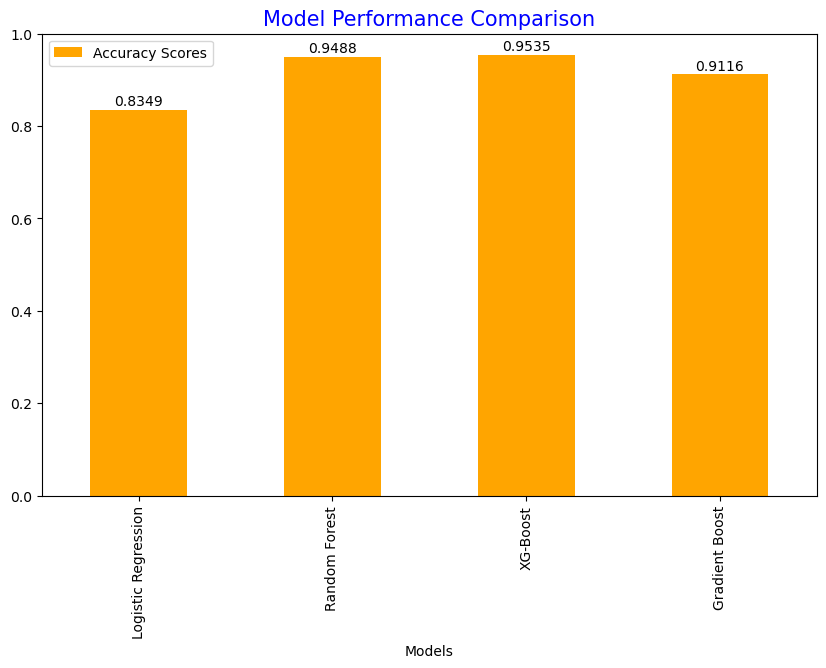

In [45]:
# Plotting the models based on accuracy
ax1=df.plot(figsize=(10,6),kind='bar',x='Models',y='Accuracy Scores',color='Orange')
ax1.set_title('Model Performance Comparison',fontsize=15,color='blue')
for i,v in enumerate (df['Accuracy Scores']):
    ax1.text(i, v + 0.01, f'{v:.4f}',ha='center')
ax1.set_ylim(0,1) 
plt.show()

We can observe that XGBoost is the best model with high performance

# Hyperparameter Tuning For Best model

In [46]:
from sklearn.model_selection import RandomizedSearchCV

In [47]:
xgb=XGBClassifier()

params={'n_estimators':[100,150,200,300,400],
        'learning_rate':[0.6,0.7,0.8,0.9],
        'max_depth': [3, 4, 5, 6, 7, 8],
        'subsample': [0.7, 0.8, 0.9, 1.0],
        'random_state':[30,50,70,100]
       }

random_search=RandomizedSearchCV(estimator=xgb,param_distributions=params,n_iter=20,cv=5)
random_search.fit(x_train,y_train)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constrain...
                                           max_delta_step=None, max_depth=None,
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=20,
                   param_distributions={'learning_rate': [0.6, 0.7, 0.8, 0.9],
                                        'max_depth': [3, 4, 5, 6, 7, 8],
                                        'n_estimators': [100, 150, 200, 300,
                                                         400],
                                        'random_state': [30, 50, 70, 100],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]})

In [48]:
# Best Parameters
print('Best Parameters',random_search.best_params_)
# Best estimator
best_xgb=random_search.best_estimator_

Best Parameters {'subsample': 1.0, 'random_state': 30, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.6}


In [49]:
pred=best_xgb.predict(x_test)

In [50]:
best_model_acc=accuracy_score(y_test,pred)
print('===Best model Accuracy Score===\n',best_model_acc)

===Best model Accuracy Score===
 0.9558139534883721


In [51]:
import pickle
file='Alzheimers_project.pkl'
pickle.dump(best_xgb, open("Alzheimers_project.pkl", "wb"))
pickle.dump(std_slr, open("st_scaler.pkl", "wb"))